In [1]:
import matplotlib.pyplot as plt
import pandas as pd

In [10]:
ts = []
cpu = []
mem_real = []
mem_virt = []

with open('activity.txt') as f:
    for line in f:
        if line.startswith('#'):
            continue
        data = [float(i) for i in line.split()]
        ts.append(data[0])
        cpu.append(data[1])
        mem_real.append(data[2])
        mem_virt.append(data[3])

Text(0, 0.5, 'Memory usage (MB)')

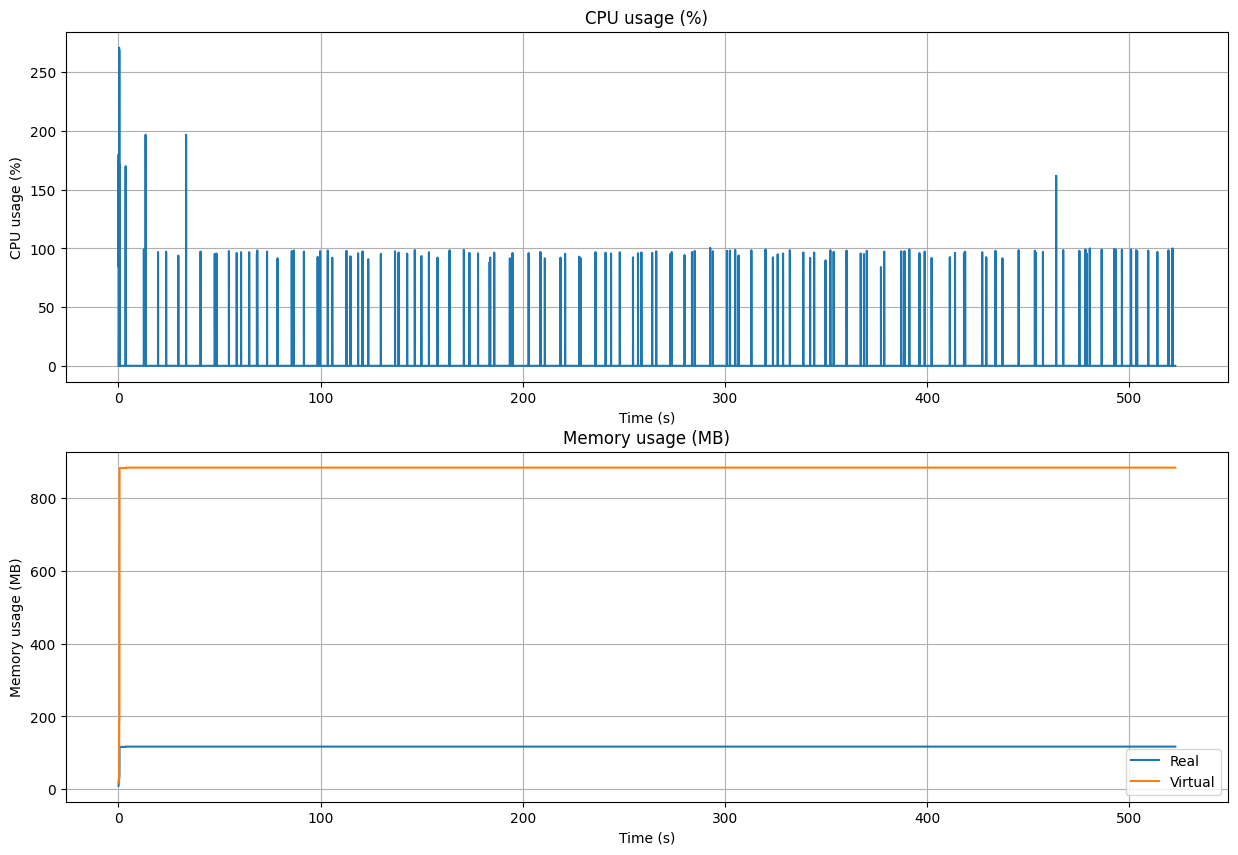

In [19]:
plt.figure(figsize=(15, 10))
plt.subplot(2, 1, 1)
plt.plot(ts, cpu, label='CPU')
plt.grid()
plt.title("CPU usage (%)")
plt.xlabel("Time (s)")
plt.ylabel("CPU usage (%)")

plt.subplot(2, 1, 2)
plt.plot(ts, mem_real, label='Real')
plt.plot(ts, mem_virt, label='Virtual')
plt.legend()
plt.grid()
plt.title("Memory usage (MB)")
plt.xlabel("Time (s)")
plt.ylabel("Memory usage (MB)")

In [12]:
def parse_performance_data(file_path):
    with open(file_path, 'r') as file:
        lines = file.readlines()
    
    data = {}
    current_test = None
    
    for line in lines:
        if 'PERFORMANCE TEST' in line:
            current_test = line.strip()
            data[current_test] = []
        elif 'Elapsed time' in line:
            parts = line.split()
            detections = int(parts[1][:-1])
            elapsed_time = float(parts[-2])
            data[current_test].append((detections, elapsed_time))
    
    return data

def plot_performance(data_pc, data_rpi, test_name, xlabel='Detections', ylabel='Elapsed Time (sec)'):
    pc_data = data_pc[test_name]
    rpi_data = data_rpi[test_name]
    
    pc_detections, pc_times = zip(*pc_data)
    rpi_detections, rpi_times = zip(*rpi_data)
    
    plt.figure(figsize=(10, 4))
    plt.plot(pc_detections, pc_times, label='PC', marker='o')
    plt.plot(rpi_detections, rpi_times, label='Raspberry Pi 4', marker='o')
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(test_name)
    plt.legend()
    plt.grid(True)
    plt.show()

def summarize_results(data_pc, data_rpi):
    summary = []
    for test_name in data_pc.keys():
        for (pc_det, pc_time), (rpi_det, rpi_time) in zip(data_pc[test_name], data_rpi[test_name]):
            summary.append([test_name, pc_det, pc_time, rpi_time])
    
    df = pd.DataFrame(summary, columns=['Test', 'Detections', 'PC Time (sec)', 'Raspberry Pi Time (sec)'])
    return df


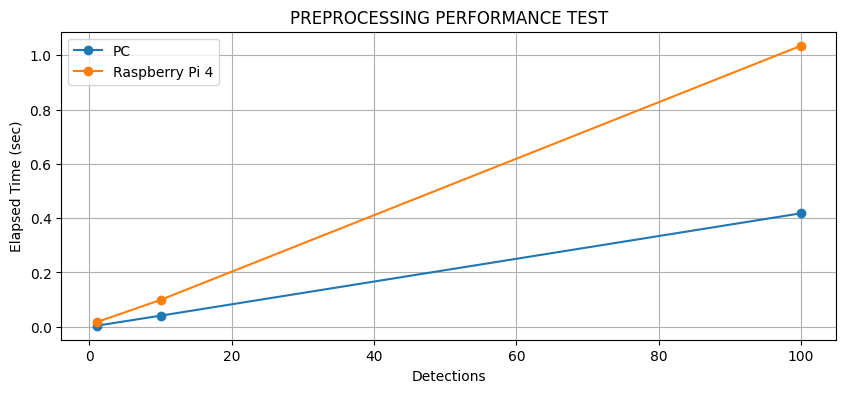

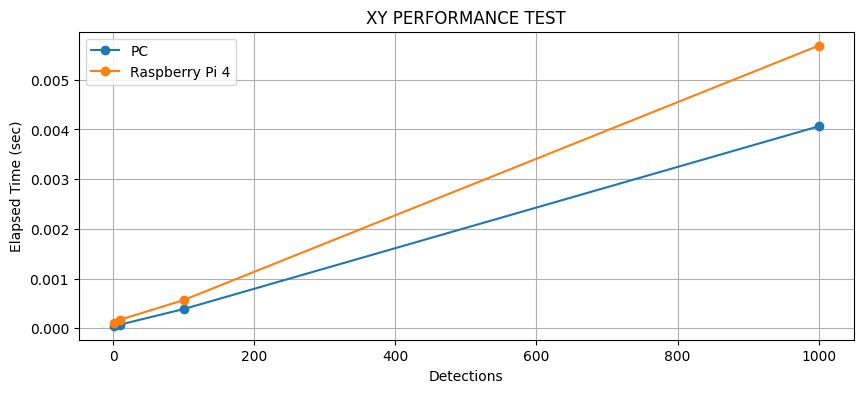

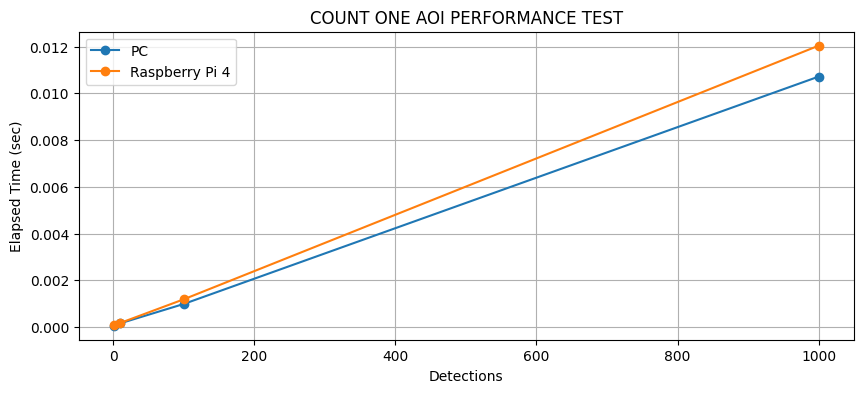

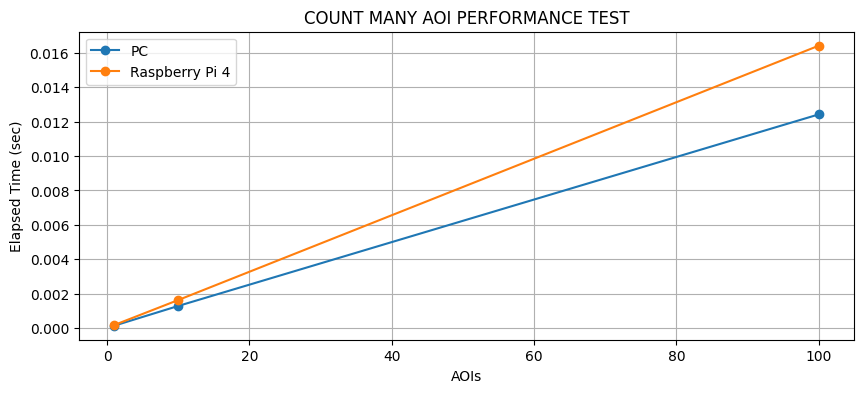

                               Test  Detections  PC Time (sec)  \
0    PREPROCESSING PERFORMANCE TEST           1       0.004000   
1    PREPROCESSING PERFORMANCE TEST          10       0.041000   
2    PREPROCESSING PERFORMANCE TEST         100       0.418000   
3               XY PERFORMANCE TEST           1       0.000050   
4               XY PERFORMANCE TEST          10       0.000074   
5               XY PERFORMANCE TEST         100       0.000386   
6               XY PERFORMANCE TEST        1000       0.004062   
7    COUNT ONE AOI PERFORMANCE TEST           1       0.000055   
8    COUNT ONE AOI PERFORMANCE TEST          10       0.000159   
9    COUNT ONE AOI PERFORMANCE TEST         100       0.000987   
10   COUNT ONE AOI PERFORMANCE TEST        1000       0.010714   
11  COUNT MANY AOI PERFORMANCE TEST           1       0.000131   
12  COUNT MANY AOI PERFORMANCE TEST          10       0.001280   
13  COUNT MANY AOI PERFORMANCE TEST         100       0.012426   

    Raspb

In [14]:
pc_file = 'elapsed_time_pc.txt'
rpi_file = 'elapsed_time_pi.txt'

data_pc = parse_performance_data(pc_file)
data_rpi = parse_performance_data(rpi_file)

for test_name in data_pc.keys():
    if "MANY AOI" in test_name:
        plot_performance(data_pc, data_rpi, test_name, xlabel='AOIs')
    else:
        plot_performance(data_pc, data_rpi, test_name)

summary_df = summarize_results(data_pc, data_rpi)
print(summary_df)

# Save the summary to a CSV file
summary_df.to_csv('performance_summary.csv', index=False)

# Conclusion
conclusion = """
Conclusion:
The performance comparison between the PC and Raspberry Pi 4 shows that the PC consistently outperforms the Raspberry Pi 4 across all tests.
The difference in performance is more pronounced as the number of detections increases. This indicates that the PC is better suited for
tasks requiring higher computational power and speed.
"""
print(conclusion)

In [15]:
summary_df

,Test,Detections,PC Time (sec),Raspberry Pi Time (sec)
0,PREPROCESSING PERFORMANCE TEST,1,0.004000,0.017000
1,PREPROCESSING PERFORMANCE TEST,10,0.041000,0.099000
2,PREPROCESSING PERFORMANCE TEST,100,0.418000,1.035000
3,XY PERFORMANCE TEST,1,0.000050,0.000114
4,XY PERFORMANCE TEST,10,0.000074,0.000172
5,XY PERFORMANCE TEST,100,0.000386,0.000567
6,XY PERFORMANCE TEST,1000,0.004062,0.005685
7,COUNT ONE AOI PERFORMANCE TEST,1,0.000055,0.000081
8,COUNT ONE AOI PERFORMANCE TEST,10,0.000159,0.000175
9,COUNT ONE AOI PERFORMANCE TEST,100,0.000987,0.001187
